# Qwen-27B Weight-Route Competence-Gating Audit

The paired mapping-by-side experiment showed that the weight intervention was reliable in only one of four cells.

[实验设置与运行说明](../../../docs/experiment_notes/10_exploratory_composition_and_gating/7e5215eccba1e6c6.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_TRACKED_CELLS = 14
_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(total=total, initial=initial, desc=label, unit='cell',
               dynamic_ncols=True, leave=True)
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print(f'Cell progress helper ready: {_TRACKED_CELLS} tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


## 1. Frozen analysis protocol and parent records


In [2]:
%%cell_progress 1/14 Locate the completed factorial run
cell_stage('Mounting Drive and locating VisualTorque')
import os
from pathlib import Path

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    pass

root_candidates = []
if os.environ.get('VISUALTORQUE_ROOT'):
    root_candidates.append(Path(os.environ['VISUALTORQUE_ROOT']))
root_candidates.extend([
    Path('/content/drive/MyDrive/VisualTorque'),
    Path.cwd(),
    Path.cwd() / 'VisualTorque',
])
PROJECT_ROOT = next(
    (path.resolve() for path in root_candidates
     if (path / 'results').is_dir()),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque. In a local runtime, set the '
    'VISUALTORQUE_ROOT environment variable to the project directory.'
)

PARENT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_weight_route_mapping_side_factorial_v1'
)
OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_weight_route_competence_gating_audit_v1'
)
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (OUTPUT_ROOT, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

print('Project:', PROJECT_ROOT)
print('Parent run:', PARENT_ROOT)
print('Output:', OUTPUT_ROOT)


Locate the completed factorial run:   0%|          | 0/14 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque
Parent run: /content/drive/MyDrive/VisualTorque/results/qwen27b_weight_route_mapping_side_factorial_v1
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_weight_route_competence_gating_audit_v1


In [3]:
%%cell_progress 2/14 Import and verify the analysis environment
cell_stage('Importing numerical and plotting libraries')
import hashlib
import json
import math
import platform
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print('Python:', platform.python_version())
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
print('matplotlib:', plt.matplotlib.__version__)


Import and verify the analysis environment:   7%|7         | 1/14 [00:00<?, ?cell/s]

Python: 3.13.15
NumPy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0


In [4]:
%%cell_progress 3/14 Lock the competence-gating analysis
cell_stage('Freezing predictors, outcomes, uncertainty, and decisions')

SEED = 20261113
BOOTSTRAP_REPLICATES = 10000
ROBUSTNESS_BOOTSTRAP_REPLICATES = 4000
ALPHA = 0.05
MINIMUM_FAMILIES = 20
EQUIVALENCE_BOUND = 0.05

PRIMARY_METRIC = 'shared_over_random'
SECONDARY_METRICS = ('route_attenuation', 'route_specificity')
OUTCOME_METRICS = (PRIMARY_METRIC,) + SECONDARY_METRICS
PRIMARY_COMPETENCE = 'min_endpoint_gold_margin_z'
SECONDARY_COMPETENCE = 'log_transition_norm_z'
FACTORIAL_COLUMNS = ('side_right', 'mapping_reverse', 'side_x_mapping')

PARENT_RUN_PATH = PARENT_ROOT / 'RUN_COMPLETE.json'
PARENT_CAPTURE_PATH = PARENT_ROOT / 'capture_complete.json'
PARENT_PROTOCOL_PATH = PARENT_ROOT / 'frozen_protocol.json'
PARENT_CONFIRMATION_PATH = PARENT_ROOT / 'confirmation_manifest.jsonl'
PARENT_DECISION_PATH = PARENT_ROOT / 'analysis' / 'factorial_decision.json'
PARENT_SHARD_DIR = PARENT_ROOT / 'family_shards'
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_analysis_protocol.json'

def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False,
                   default=json_default) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def stable_seed(value):
    text = f'{SEED}:{value!r}'.encode('utf-8')
    return int(hashlib.sha256(text).hexdigest()[:16], 16) % (2**63 - 1)

for required in (
    PARENT_RUN_PATH, PARENT_CAPTURE_PATH, PARENT_PROTOCOL_PATH,
    PARENT_CONFIRMATION_PATH, PARENT_DECISION_PATH,
):
    assert required.is_file(), f'Missing completed parent output: {required}'
shard_paths = sorted(PARENT_SHARD_DIR.glob('*.json'))
assert len(shard_paths) >= MINIMUM_FAMILIES, len(shard_paths)

parent_hashes = {
    'run_complete': sha256_file(PARENT_RUN_PATH),
    'capture_complete': sha256_file(PARENT_CAPTURE_PATH),
    'protocol': sha256_file(PARENT_PROTOCOL_PATH),
    'confirmation_manifest': sha256_file(PARENT_CONFIRMATION_PATH),
    'factorial_decision': sha256_file(PARENT_DECISION_PATH),
}
protocol_identity = {
    'schema_version': 'weight-route-competence-gating-audit-1.0',
    'analysis_only': True,
    'parent_root': str(PARENT_ROOT),
    'parent_hashes': parent_hashes,
    'unit_of_analysis': 'family x target context x physical side x answer mapping',
    'cluster_unit': 'physical family',
    'primary_outcome': PRIMARY_METRIC,
    'secondary_outcomes': list(SECONDARY_METRICS),
    'primary_preintervention_predictor': PRIMARY_COMPETENCE,
    'secondary_preintervention_predictor': SECONDARY_COMPETENCE,
    'models': {
        'invariant': 'intercept only',
        'factorial': 'side + mapping + side-by-mapping',
        'competence': (
            'factorial + minimum clean/natural gold margin + '
            'natural counterfactual contrast norm'
        ),
    },
    'prediction': 'leave-one-physical-family-out',
    'selection_uses_intervention_outcomes': False,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'seed': SEED,
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous['identity'] == protocol_identity, (
        'Existing analysis protocol differs; use a new versioned output root.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Parent shards:', len(shard_paths))
print('Primary predictor:', PRIMARY_COMPETENCE)
print('Primary outcome:', PRIMARY_METRIC)


Lock the competence-gating analysis:  14%|#4        | 2/14 [00:00<?, ?cell/s]

Parent shards: 24
Primary predictor: min_endpoint_gold_margin_z
Primary outcome: shared_over_random


In [5]:
%%cell_progress 4/14 Load and validate the parent family shards
cell_stage('Reading records without loading Qwen')

capture_document = json.loads(PARENT_CAPTURE_PATH.read_text(encoding='utf-8'))
capture_sha = capture_document['capture_identity_sha256']
family_documents = []
records = []
for path in tqdm(shard_paths, desc='Loading factorial family shards', unit='family'):
    document = json.loads(path.read_text(encoding='utf-8'))
    assert document['capture_identity_sha256'] == capture_sha
    assert document['schema_version'] == (
        'weight-route-mapping-side-family-shard-1.0'
    )
    family_documents.append(document)
    records.extend(document['records'])

record_frame = pd.DataFrame(records)
required_columns = {
    'family_id', 'orientation', 'changed_side', 'mapping_variant',
    'target_key', 'condition', 'candidate_semantics',
    'candidate_logprobs', 'predicted_semantic', 'gold_semantic',
    'counterfactual_progress', 'clean_correct', 'natural_correct',
}
assert required_columns.issubset(record_frame.columns), sorted(
    required_columns - set(record_frame.columns)
)
assert record_frame['family_id'].nunique() == len(shard_paths)
assert set(record_frame['condition']) == {
    'clean', 'natural_hybrid', 'shared', 'random_shared',
    'reverse_shared', 'self_replay', 'joint_restore', 'joint_random',
}
assert set(record_frame['mapping_variant']) == {'forward', 'reverse'}
assert set(record_frame['changed_side']) == {'left', 'right'}
assert not record_frame['counterfactual_progress'].isna().any()

parent_decision = json.loads(PARENT_DECISION_PATH.read_text(encoding='utf-8'))
print('Parent decision:', parent_decision['primary_decision'])
print('Families / raw records:', record_frame['family_id'].nunique(), len(record_frame))


Load and validate the parent family shards:  21%|##1       | 3/14 [00:00<?, ?cell/s]

Loading factorial family shards:   0%|          | 0/24 [00:00<?, ?family/s]

Parent decision: paired_weight_route_not_replicated
Families / raw records: 24 2272


## 2. Pre-intervention competence and intervention outcomes


In [6]:
%%cell_progress 5/14 Build target-level competence and route estimands
cell_stage('Separating untouched behavior from intervention outcomes')

KEY_COLUMNS = [
    'family_id', 'orientation', 'changed_side',
    'mapping_variant', 'target_key',
]

def centered(values):
    values = np.asarray(values, dtype=float)
    return values - values.mean()

def gold_margin(record):
    semantics = list(record['candidate_semantics'])
    scores = np.asarray(record['candidate_logprobs'], dtype=float)
    gold_index = semantics.index(record['gold_semantic'])
    alternatives = np.delete(scores, gold_index)
    return float(scores[gold_index] - alternatives.max())

estimand_rows = []
for keys, current in record_frame.groupby(KEY_COLUMNS, sort=True):
    by_condition = {
        row['condition']: row
        for row in current.to_dict(orient='records')
    }
    assert len(by_condition) == 8
    clean = by_condition['clean']
    natural = by_condition['natural_hybrid']
    clean_centered = centered(clean['candidate_logprobs'])
    natural_centered = centered(natural['candidate_logprobs'])
    clean_margin = gold_margin(clean)
    natural_margin = gold_margin(natural)
    progress = {
        name: float(by_condition[name]['counterfactual_progress'])
        for name in by_condition
    }
    row = dict(zip(KEY_COLUMNS, keys))
    row.update({
        'delta_sign': int(clean['delta_sign']),
        'clean_gold_semantic': clean['gold_semantic'],
        'natural_gold_semantic': natural['gold_semantic'],
        'clean_predicted_semantic': clean['predicted_semantic'],
        'natural_predicted_semantic': natural['predicted_semantic'],
        'clean_correct': bool(clean['predicted_semantic'] == clean['gold_semantic']),
        'natural_correct': bool(
            natural['predicted_semantic'] == natural['gold_semantic']
        ),
        'both_endpoints_correct': bool(
            clean['predicted_semantic'] == clean['gold_semantic']
            and natural['predicted_semantic'] == natural['gold_semantic']
        ),
        'gold_outcome_changed': bool(
            clean['gold_semantic'] != natural['gold_semantic']
        ),
        'predicted_outcome_changed': bool(
            clean['predicted_semantic'] != natural['predicted_semantic']
        ),
        'clean_gold_margin': clean_margin,
        'natural_gold_margin': natural_margin,
        'min_endpoint_gold_margin': min(clean_margin, natural_margin),
        'mean_endpoint_gold_margin': (clean_margin + natural_margin) / 2,
        'transition_norm': float(np.linalg.norm(
            natural_centered - clean_centered
        )),
        'shared_over_random': (
            progress['shared'] - progress['random_shared']
        ),
        'route_attenuation': (
            progress['shared'] - progress['joint_restore']
        ),
        'route_specificity': (
            progress['joint_random'] - progress['joint_restore']
        ),
        'shared_progress': progress['shared'],
        'random_progress': progress['random_shared'],
    })
    estimand_rows.append(row)

estimand_frame = pd.DataFrame(estimand_rows)
estimand_frame['side_right'] = (
    estimand_frame['changed_side'] == 'right'
).astype(float)
estimand_frame['mapping_reverse'] = (
    estimand_frame['mapping_variant'] == 'reverse'
).astype(float)
estimand_frame['side_x_mapping'] = (
    estimand_frame['side_right'] * estimand_frame['mapping_reverse']
)
estimand_frame['log_transition_norm'] = np.log1p(
    estimand_frame['transition_norm']
)
for column in (
    'clean_gold_margin', 'natural_gold_margin',
    'min_endpoint_gold_margin', 'mean_endpoint_gold_margin',
    'log_transition_norm',
):
    standard_deviation = float(estimand_frame[column].std(ddof=0))
    assert standard_deviation > 0, column
    estimand_frame[column + '_z'] = (
        estimand_frame[column] - estimand_frame[column].mean()
    ) / standard_deviation

estimand_frame.to_csv(
    ANALYSIS_DIR / 'target_level_competence_estimands.csv', index=False
)
print('Target-level rows:', len(estimand_frame))
print('Families:', estimand_frame['family_id'].nunique())
display(estimand_frame.head())


Build target-level competence and route estimands:  29%|##8       | 4/14 [00:00<?, ?cell/s]

Target-level rows: 284
Families: 24


,family_id,orientation,changed_side,mapping_variant,target_key,delta_sign,clean_gold_semantic,natural_gold_semantic,clean_predicted_semantic,natural_predicted_semantic,...,random_progress,side_right,mapping_reverse,side_x_mapping,log_transition_norm,clean_gold_margin_z,natural_gold_margin_z,min_endpoint_gold_margin_z,mean_endpoint_gold_margin_z,log_transition_norm_z
0,equivalence_weight_006ff431249e5db79c,mirror,right,forward,t1,-1,right,left,left,left,...,-3.701476e-08,1.0,0.0,0.0,1.285384,-0.558496,0.204356,0.094290,-0.201687,0.989303
1,equivalence_weight_006ff431249e5db79c,mirror,right,forward,t2,-1,right,balanced,left,left,...,-8.064510e-02,1.0,0.0,0.0,0.995018,-0.558496,-0.621527,-0.309000,-0.766773,0.322674
2,equivalence_weight_006ff431249e5db79c,mirror,right,forward,t3,-1,right,right,left,left,...,-2.073737e-02,1.0,0.0,0.0,1.282067,-0.390474,-0.171045,0.174948,-0.355802,0.981689
3,equivalence_weight_006ff431249e5db79c,mirror,right,reverse,t1,-1,right,left,left,left,...,1.373183e-02,1.0,1.0,1.0,1.263922,-0.894541,0.354516,-0.228342,-0.304430,0.940030
4,equivalence_weight_006ff431249e5db79c,mirror,right,reverse,t2,-1,right,balanced,left,left,...,4.651155e-02,1.0,1.0,1.0,0.849523,-1.062563,-0.921848,-0.631632,-1.280488,-0.011356


In [7]:
%%cell_progress 6/14 Audit support and prevent outcome leakage
cell_stage('Checking paired support and predictor provenance')

assert estimand_frame['family_id'].nunique() >= MINIMUM_FAMILIES
assert estimand_frame.groupby([
    'family_id', 'target_key'
]).size().eq(4).all()
assert set(zip(
    estimand_frame['changed_side'], estimand_frame['mapping_variant']
)) == {
    ('left', 'forward'), ('left', 'reverse'),
    ('right', 'forward'), ('right', 'reverse'),
}
assert np.isfinite(
    estimand_frame[list(OUTCOME_METRICS)].to_numpy(dtype=float)
).all()

predictor_provenance = {
    'clean_gold_margin': 'untouched clean record only',
    'natural_gold_margin': 'untouched natural counterfactual only',
    'min_endpoint_gold_margin': 'minimum of the two untouched endpoint margins',
    'transition_norm': 'distance between untouched clean and natural logits',
    'side_and_mapping': 'experimental design labels',
}
outcome_provenance = {
    PRIMARY_METRIC: 'shared intervention minus equal-norm random intervention',
    'route_attenuation': 'shared intervention minus frozen-route restoration',
    'route_specificity': 'random-route control minus frozen-route restoration',
}

support = estimand_frame.groupby([
    'changed_side', 'mapping_variant'
]).agg(
    rows=('family_id', 'size'),
    families=('family_id', 'nunique'),
    clean_accuracy=('clean_correct', 'mean'),
    natural_accuracy=('natural_correct', 'mean'),
    both_correct=('both_endpoints_correct', 'mean'),
    outcome_flip_rate=('gold_outcome_changed', 'mean'),
    min_margin=('min_endpoint_gold_margin', 'mean'),
    transition_norm=('transition_norm', 'mean'),
).reset_index()
support.to_csv(ANALYSIS_DIR / 'support_and_behavior_audit.csv', index=False)
write_json_atomic(ANALYSIS_DIR / 'predictor_provenance.json', {
    'predictors': predictor_provenance,
    'outcomes': outcome_provenance,
    'intervention_outcomes_used_to_define_predictors': False,
})
display(support.round(4))


Audit support and prevent outcome leakage:  36%|###5      | 5/14 [00:00<?, ?cell/s]

,changed_side,mapping_variant,rows,families,clean_accuracy,natural_accuracy,both_correct,outcome_flip_rate,min_margin,transition_norm
0,left,forward,71,24,0.5915,0.5634,0.3803,0.4507,-0.4137,1.3703
1,left,reverse,71,24,0.5211,0.5070,0.3099,0.4507,-0.6021,1.3975
2,right,forward,71,24,0.5211,0.5211,0.3099,0.4507,-0.5704,1.7672
3,right,reverse,71,24,0.4366,0.4225,0.2817,0.4507,-0.9982,1.8104


In [8]:
%%cell_progress 7/14 Summarize route expression by untouched behavior
cell_stage('Describing competence strata without using them for selection')

def endpoint_status(row):
    if row['clean_correct'] and row['natural_correct']:
        return 'both correct'
    if row['clean_correct']:
        return 'clean only'
    if row['natural_correct']:
        return 'natural only'
    return 'neither correct'

estimand_frame['endpoint_status'] = estimand_frame.apply(
    endpoint_status, axis=1
)
ranked = estimand_frame['min_endpoint_gold_margin'].rank(
    method='first'
)
estimand_frame['competence_quartile'] = pd.qcut(
    ranked, 4, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4 highest']
)

status_summary = estimand_frame.groupby('endpoint_status', observed=True).agg(
    rows=('family_id', 'size'),
    families=('family_id', 'nunique'),
    min_margin=('min_endpoint_gold_margin', 'mean'),
    shared_over_random=('shared_over_random', 'mean'),
    route_attenuation=('route_attenuation', 'mean'),
    route_specificity=('route_specificity', 'mean'),
).reset_index()
quartile_summary = estimand_frame.groupby(
    'competence_quartile', observed=True
).agg(
    rows=('family_id', 'size'),
    min_margin=('min_endpoint_gold_margin', 'mean'),
    shared_over_random=('shared_over_random', 'mean'),
    route_attenuation=('route_attenuation', 'mean'),
    route_specificity=('route_specificity', 'mean'),
).reset_index()
status_summary.to_csv(ANALYSIS_DIR / 'endpoint_status_summary.csv', index=False)
quartile_summary.to_csv(
    ANALYSIS_DIR / 'competence_quartile_summary.csv', index=False
)
display(status_summary.round(5))
display(quartile_summary.round(5))


Summarize route expression by untouched behavior:  43%|####2     | 6/14 [00:00<?, ?cell/s]

,endpoint_status,rows,families,min_margin,shared_over_random,route_attenuation,route_specificity
0,both correct,91,24,1.08929,0.03589,0.08983,0.11180
1,clean only,56,22,-1.46875,0.02682,0.03023,0.03353
2,natural only,52,20,-1.12500,0.03778,0.04626,0.06616
3,neither correct,85,24,-1.66912,0.02572,-0.00173,-0.01322


,competence_quartile,rows,min_margin,shared_over_random,route_attenuation,route_specificity
0,Q1 lowest,71,-2.69190,-0.02018,-0.07704,-0.10974
1,Q2,71,-1.04577,0.07140,0.08420,0.11600
2,Q3,71,-0.12500,0.03774,0.05836,0.06696
3,Q4 highest,71,1.27817,0.03667,0.10527,0.12915


## 3. Clustered inference and held-out-family prediction


In [9]:
%%cell_progress 8/14 Estimate clustered competence slopes
cell_stage('Bootstrapping complete physical families')

MODEL_COLUMNS = {
    'invariant': (),
    'factorial': FACTORIAL_COLUMNS,
    'competence': FACTORIAL_COLUMNS + (
        PRIMARY_COMPETENCE, SECONDARY_COMPETENCE,
    ),
}

def design_matrix(frame, columns):
    if not columns:
        return np.ones((len(frame), 1), dtype=float), ['intercept']
    matrix = np.column_stack([
        np.ones(len(frame), dtype=float),
        *[frame[column].to_numpy(dtype=float) for column in columns],
    ])
    return matrix, ['intercept', *columns]

def fit_coefficients(frame, metric, columns):
    matrix, names = design_matrix(frame, columns)
    outcome = frame[metric].to_numpy(dtype=float)
    coefficients = np.linalg.lstsq(matrix, outcome, rcond=None)[0]
    return dict(zip(names, coefficients))

def clustered_coefficient_summary(frame, metric, model_name, replicates):
    columns = MODEL_COLUMNS[model_name]
    point = fit_coefficients(frame, metric, columns)
    families = frame['family_id'].drop_duplicates().to_numpy()
    generator = np.random.default_rng(stable_seed((metric, model_name)))
    draws = {name: [] for name in point}
    progress = tqdm(range(replicates),
                    desc=f'{metric} / {model_name}', unit='bootstrap', leave=False)
    for _ in progress:
        sampled = generator.choice(families, size=len(families), replace=True)
        pieces = [frame[frame['family_id'] == family] for family in sampled]
        bootstrap_frame = pd.concat(pieces, ignore_index=True)
        coefficients = fit_coefficients(
            bootstrap_frame, metric, columns
        )
        for name, value in coefficients.items():
            draws[name].append(value)
    rows = []
    for name, estimate in point.items():
        values = np.asarray(draws[name], dtype=float)
        rows.append({
            'metric': metric, 'model': model_name, 'term': name,
            'estimate': float(estimate),
            'ci_low': float(np.quantile(values, ALPHA / 2)),
            'ci_high': float(np.quantile(values, 1 - ALPHA / 2)),
            'n_families': int(len(families)),
        })
    return rows

coefficient_rows = []
for metric in OUTCOME_METRICS:
    for model_name in ('factorial', 'competence'):
        coefficient_rows.extend(clustered_coefficient_summary(
            estimand_frame, metric, model_name, BOOTSTRAP_REPLICATES
        ))
coefficient_frame = pd.DataFrame(coefficient_rows)
coefficient_frame.to_csv(
    ANALYSIS_DIR / 'clustered_regression_coefficients.csv', index=False
)

primary_slopes = coefficient_frame[
    (coefficient_frame['model'] == 'competence')
    & (coefficient_frame['term'].isin((
        PRIMARY_COMPETENCE, SECONDARY_COMPETENCE,
    )))
]
display(primary_slopes.round(6))


Estimate clustered competence slopes:  50%|#####     | 7/14 [00:00<?, ?cell/s]

shared_over_random / factorial:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

shared_over_random / competence:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

route_attenuation / factorial:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

route_attenuation / competence:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

route_specificity / factorial:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

route_specificity / competence:   0%|          | 0/10000 [00:00<?, ?bootstrap/s]

,metric,model,term,estimate,ci_low,ci_high,n_families
8,shared_over_random,competence,min_endpoint_gold_margin_z,0.021545,-0.015918,0.052158,24
9,shared_over_random,competence,log_transition_norm_z,-0.049680,-0.115923,0.019965,24
18,route_attenuation,competence,min_endpoint_gold_margin_z,0.059250,0.015338,0.093623,24
19,route_attenuation,competence,log_transition_norm_z,-0.062146,-0.155675,0.027821,24
28,route_specificity,competence,min_endpoint_gold_margin_z,0.078643,0.031331,0.119476,24
29,route_specificity,competence,log_transition_norm_z,-0.068938,-0.173491,0.033441,24


In [10]:
%%cell_progress 9/14 Compare invariant, factorial, and competence predictions
cell_stage('Holding out one complete family at a time')

CONTINUOUS_COLUMNS = {
    PRIMARY_COMPETENCE, SECONDARY_COMPETENCE,
}

def train_test_design(train, test, model_name):
    columns = MODEL_COLUMNS[model_name]
    train_values = []
    test_values = []
    for column in columns:
        train_column = train[column].to_numpy(dtype=float)
        test_column = test[column].to_numpy(dtype=float)
        if column in CONTINUOUS_COLUMNS:
            mean = float(train_column.mean())
            standard_deviation = float(train_column.std(ddof=0))
            standard_deviation = max(standard_deviation, 1e-12)
            train_column = (train_column - mean) / standard_deviation
            test_column = (test_column - mean) / standard_deviation
        train_values.append(train_column)
        test_values.append(test_column)
    train_matrix = np.column_stack([
        np.ones(len(train), dtype=float), *train_values
    ])
    test_matrix = np.column_stack([
        np.ones(len(test), dtype=float), *test_values
    ])
    return train_matrix, test_matrix

prediction_rows = []
families = estimand_frame['family_id'].drop_duplicates().tolist()
for metric in OUTCOME_METRICS:
    for held_family in tqdm(
        families, desc=f'Leave-family-out: {metric}', unit='family'
    ):
        train = estimand_frame[estimand_frame['family_id'] != held_family]
        test = estimand_frame[estimand_frame['family_id'] == held_family]
        observed = test[metric].to_numpy(dtype=float)
        for model_name in MODEL_COLUMNS:
            train_matrix, test_matrix = train_test_design(
                train, test, model_name
            )
            coefficients = np.linalg.lstsq(
                train_matrix, train[metric].to_numpy(dtype=float), rcond=None
            )[0]
            predicted = test_matrix @ coefficients
            for row_index, prediction, observation in zip(
                test.index, predicted, observed
            ):
                prediction_rows.append({
                    'metric': metric, 'model': model_name,
                    'family_id': held_family,
                    'row_index': int(row_index),
                    'observed': float(observation),
                    'predicted': float(prediction),
                    'squared_error': float((observation - prediction) ** 2),
                    'absolute_error': float(abs(observation - prediction)),
                })

prediction_frame = pd.DataFrame(prediction_rows)
prediction_frame.to_csv(
    ANALYSIS_DIR / 'leave_family_out_predictions.csv', index=False
)
comparison_rows = []
for (metric, model_name), current in prediction_frame.groupby([
    'metric', 'model'
]):
    observed = current['observed'].to_numpy(dtype=float)
    predicted = current['predicted'].to_numpy(dtype=float)
    denominator = float(((observed - observed.mean()) ** 2).sum())
    comparison_rows.append({
        'metric': metric, 'model': model_name,
        'rmse': float(np.sqrt(np.mean((observed - predicted) ** 2))),
        'mae': float(np.mean(np.abs(observed - predicted))),
        'r2': float(1 - ((observed - predicted) ** 2).sum() / denominator),
        'prediction_correlation': float(np.corrcoef(observed, predicted)[0, 1])
        if float(np.std(predicted)) > 0 else float('nan'),
    })
comparison_frame = pd.DataFrame(comparison_rows)
comparison_frame.to_csv(
    ANALYSIS_DIR / 'heldout_model_comparison.csv', index=False
)
display(comparison_frame.round(6))


Compare invariant, factorial, and competence predictions:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

Leave-family-out: shared_over_random:   0%|          | 0/24 [00:00<?, ?family/s]

Leave-family-out: route_attenuation:   0%|          | 0/24 [00:00<?, ?family/s]

Leave-family-out: route_specificity:   0%|          | 0/24 [00:00<?, ?family/s]

,metric,model,rmse,mae,r2,prediction_correlation
0,route_attenuation,competence,0.463585,0.251489,-0.022158,0.040614
1,route_attenuation,factorial,0.466187,0.252315,-0.033666,-0.193641
2,route_attenuation,invariant,0.462808,0.247890,-0.018736,-0.456194
3,route_specificity,competence,0.511358,0.275247,-0.015305,0.070294
4,route_specificity,factorial,0.515664,0.271134,-0.032478,-0.176615
5,route_specificity,invariant,0.512331,0.265308,-0.019174,-0.462432
6,shared_over_random,competence,0.309723,0.170538,-0.035921,0.010589
7,shared_over_random,factorial,0.309439,0.173363,-0.034027,-0.120152
8,shared_over_random,invariant,0.307935,0.169651,-0.023998,-0.516132


In [11]:
%%cell_progress 10/14 Test held-out predictive gain by family
cell_stage('Bootstrapping family-level prediction errors')

gain_rows = []
family_error = prediction_frame.groupby([
    'metric', 'model', 'family_id'
])['squared_error'].mean().reset_index()
for metric in OUTCOME_METRICS:
    current = family_error[family_error['metric'] == metric].pivot(
        index='family_id', columns='model', values='squared_error'
    )
    fixed_gain = current['factorial'] - current['competence']
    invariant_gain = current['invariant'] - current['competence']
    for contrast_name, values in (
        ('competence_over_factorial', fixed_gain),
        ('competence_over_invariant', invariant_gain),
    ):
        array = values.to_numpy(dtype=float)
        generator = np.random.default_rng(stable_seed((metric, contrast_name)))
        indices = generator.integers(
            0, len(array), size=(BOOTSTRAP_REPLICATES, len(array))
        )
        draws = array[indices].mean(axis=1)
        gain_rows.append({
            'metric': metric, 'contrast': contrast_name,
            'mse_reduction': float(array.mean()),
            'ci_low': float(np.quantile(draws, ALPHA / 2)),
            'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
            'families_improved_fraction': float((array > 0).mean()),
            'n_families': int(len(array)),
        })
gain_frame = pd.DataFrame(gain_rows)
gain_frame.to_csv(
    ANALYSIS_DIR / 'heldout_predictive_gain.csv', index=False
)
display(gain_frame.round(6))


Test held-out predictive gain by family:  64%|######4   | 9/14 [00:00<?, ?cell/s]

,metric,contrast,mse_reduction,ci_low,ci_high,families_improved_fraction,n_families
0,shared_over_random,competence_over_factorial,-0.000047,-0.006173,0.006103,0.500000,24
1,shared_over_random,competence_over_invariant,-0.000943,-0.006579,0.004462,0.583333,24
2,route_attenuation,competence_over_factorial,0.002421,-0.007837,0.013934,0.500000,24
3,route_attenuation,competence_over_invariant,-0.000741,-0.009657,0.008462,0.458333,24
4,route_specificity,competence_over_factorial,0.004025,-0.009024,0.018669,0.500000,24
5,route_specificity,competence_over_invariant,0.000526,-0.012002,0.013589,0.500000,24


## 4. Robustness, visualization, and decision


In [12]:
%%cell_progress 11/14 Run predictor and influence robustness checks
cell_stage('Checking alternative competence definitions and family influence')

ALTERNATIVE_PREDICTORS = (
    'clean_gold_margin_z',
    'natural_gold_margin_z',
    'min_endpoint_gold_margin_z',
    'mean_endpoint_gold_margin_z',
    'log_transition_norm_z',
)

def slope_with_fixed_terms(frame, metric, predictor):
    columns = FACTORIAL_COLUMNS + (predictor,)
    return fit_coefficients(frame, metric, columns)[predictor]

robustness_rows = []
families_array = estimand_frame['family_id'].drop_duplicates().to_numpy()
for metric in OUTCOME_METRICS:
    for predictor in ALTERNATIVE_PREDICTORS:
        estimate = slope_with_fixed_terms(estimand_frame, metric, predictor)
        generator = np.random.default_rng(stable_seed((
            'alternative', metric, predictor
        )))
        draws = []
        for _ in range(ROBUSTNESS_BOOTSTRAP_REPLICATES):
            sampled = generator.choice(
                families_array, size=len(families_array), replace=True
            )
            current = pd.concat([
                estimand_frame[estimand_frame['family_id'] == family]
                for family in sampled
            ], ignore_index=True)
            draws.append(slope_with_fixed_terms(current, metric, predictor))
        robustness_rows.append({
            'metric': metric, 'predictor': predictor,
            'estimate': float(estimate),
            'ci_low': float(np.quantile(draws, ALPHA / 2)),
            'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
        })

robustness_frame = pd.DataFrame(robustness_rows)
robustness_frame.to_csv(
    ANALYSIS_DIR / 'alternative_predictor_robustness.csv', index=False
)

influence_rows = []
for metric in OUTCOME_METRICS:
    for omitted_family in families_array:
        current = estimand_frame[
            estimand_frame['family_id'] != omitted_family
        ]
        influence_rows.append({
            'metric': metric, 'omitted_family': omitted_family,
            'competence_slope': slope_with_fixed_terms(
                current, metric, PRIMARY_COMPETENCE
            ),
        })
influence_frame = pd.DataFrame(influence_rows)
influence_frame.to_csv(
    ANALYSIS_DIR / 'leave_one_family_out_slope_influence.csv', index=False
)
influence_summary = influence_frame.groupby('metric').agg(
    minimum_slope=('competence_slope', 'min'),
    median_slope=('competence_slope', 'median'),
    maximum_slope=('competence_slope', 'max'),
    positive_fraction=('competence_slope', lambda values: (values > 0).mean()),
).reset_index()
display(robustness_frame.round(6))
display(influence_summary.round(6))


Run predictor and influence robustness checks:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

,metric,predictor,estimate,ci_low,ci_high
0,shared_over_random,clean_gold_margin_z,0.002096,-0.025113,0.026588
1,shared_over_random,natural_gold_margin_z,0.020169,-0.018077,0.054582
2,shared_over_random,min_endpoint_gold_margin_z,0.022153,-0.014519,0.055805
3,shared_over_random,mean_endpoint_gold_margin_z,0.015137,-0.014481,0.040766
4,shared_over_random,log_transition_norm_z,-0.049947,-0.118520,0.020393
5,route_attenuation,clean_gold_margin_z,0.029406,-0.011775,0.073469
6,route_attenuation,natural_gold_margin_z,0.042565,-0.029760,0.108045
7,route_attenuation,min_endpoint_gold_margin_z,0.060011,0.020759,0.097003
8,route_attenuation,mean_endpoint_gold_margin_z,0.047377,0.007595,0.085922
9,route_attenuation,log_transition_norm_z,-0.062879,-0.158040,0.029196


,metric,minimum_slope,median_slope,maximum_slope,positive_fraction
0,route_attenuation,0.051446,0.060799,0.069365,1.0
1,route_specificity,0.065489,0.080678,0.086652,1.0
2,shared_over_random,0.014649,0.022272,0.035373,1.0


Save the paper-facing competence-gating figure:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

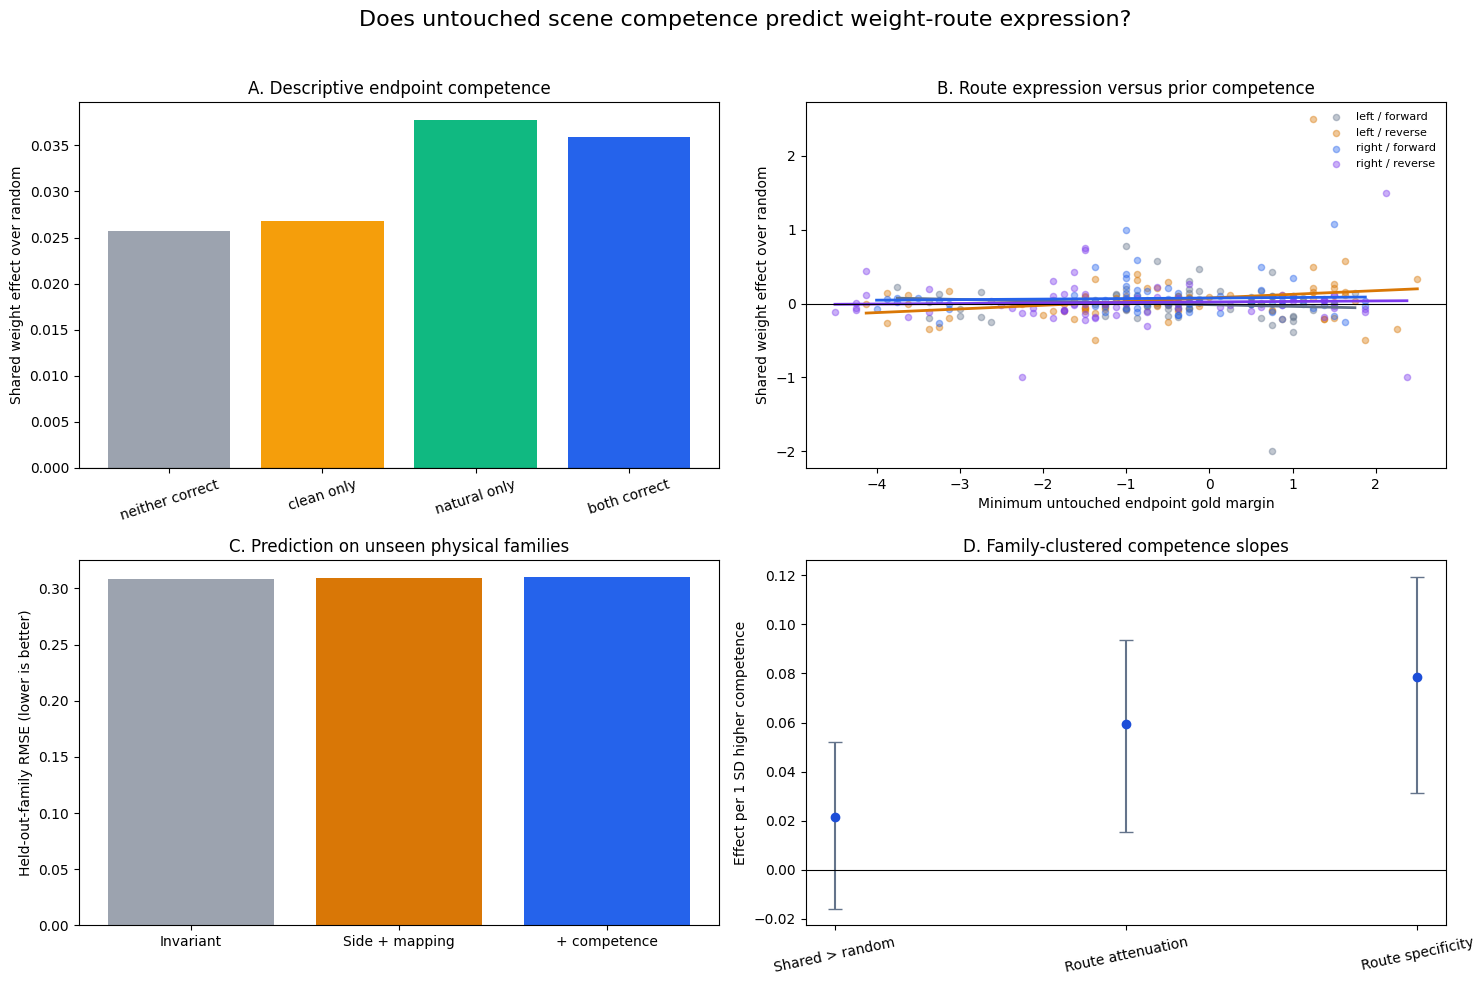

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_weight_route_competence_gating_audit_v1/analysis/figures/weight_route_competence_gating.png


In [13]:
%%cell_progress 12/14 Save the paper-facing competence-gating figure
cell_stage('Rendering behavior, slopes, prediction, and interaction panels')

colors = {
    ('left', 'forward'): '#64748B',
    ('left', 'reverse'): '#D97706',
    ('right', 'forward'): '#2563EB',
    ('right', 'reverse'): '#7C3AED',
}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

order = ['neither correct', 'clean only', 'natural only', 'both correct']
status_plot = status_summary.set_index('endpoint_status').reindex(order)
axes[0, 0].bar(
    np.arange(len(order)), status_plot['shared_over_random'],
    color=['#9CA3AF', '#F59E0B', '#10B981', '#2563EB'],
)
axes[0, 0].axhline(0, color='black', linewidth=0.8)
axes[0, 0].set_xticks(np.arange(len(order)), order, rotation=18)
axes[0, 0].set_ylabel('Shared weight effect over random')
axes[0, 0].set_title('A. Descriptive endpoint competence')

for (side, mapping), current in estimand_frame.groupby([
    'changed_side', 'mapping_variant'
]):
    color = colors[(side, mapping)]
    label = f'{side} / {mapping}'
    axes[0, 1].scatter(
        current['min_endpoint_gold_margin'],
        current[PRIMARY_METRIC], s=20, alpha=0.40,
        color=color, label=label,
    )
    x = current['min_endpoint_gold_margin'].to_numpy(dtype=float)
    y = current[PRIMARY_METRIC].to_numpy(dtype=float)
    if len(np.unique(x)) > 1:
        slope, intercept = np.polyfit(x, y, 1)
        grid = np.linspace(x.min(), x.max(), 100)
        axes[0, 1].plot(grid, intercept + slope * grid,
                        color=color, linewidth=2)
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set_xlabel('Minimum untouched endpoint gold margin')
axes[0, 1].set_ylabel('Shared weight effect over random')
axes[0, 1].set_title('B. Route expression versus prior competence')
axes[0, 1].legend(frameon=False, fontsize=8)

primary_models = comparison_frame[
    comparison_frame['metric'] == PRIMARY_METRIC
].set_index('model').loc[['invariant', 'factorial', 'competence']]
axes[1, 0].bar(
    np.arange(3), primary_models['rmse'],
    color=['#9CA3AF', '#D97706', '#2563EB'],
)
axes[1, 0].set_xticks(
    np.arange(3), ['Invariant', 'Side + mapping', '+ competence']
)
axes[1, 0].set_ylabel('Held-out-family RMSE (lower is better)')
axes[1, 0].set_title('C. Prediction on unseen physical families')

slope_plot = coefficient_frame[
    (coefficient_frame['model'] == 'competence')
    & (coefficient_frame['term'] == PRIMARY_COMPETENCE)
].set_index('metric').loc[list(OUTCOME_METRICS)]
x = np.arange(len(OUTCOME_METRICS))
y = slope_plot['estimate'].to_numpy()
yerr = np.vstack([
    y - slope_plot['ci_low'].to_numpy(),
    slope_plot['ci_high'].to_numpy() - y,
])
axes[1, 1].errorbar(
    x, y, yerr=yerr, fmt='o', color='#1D4ED8',
    ecolor='#64748B', capsize=5,
)
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set_xticks(
    x, ['Shared > random', 'Route attenuation', 'Route specificity'],
    rotation=12,
)
axes[1, 1].set_ylabel('Effect per 1 SD higher competence')
axes[1, 1].set_title('D. Family-clustered competence slopes')

fig.suptitle('Does untouched scene competence predict weight-route expression?',
             fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
figure_path = FIGURE_DIR / 'weight_route_competence_gating.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
fig.savefig(figure_path.with_suffix('.pdf'), bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [14]:
%%cell_progress 13/14 Apply the frozen decision rules
cell_stage('Separating supported, partial, and unsupported explanations')

def coefficient_row(metric, term):
    return coefficient_frame[
        (coefficient_frame['metric'] == metric)
        & (coefficient_frame['model'] == 'competence')
        & (coefficient_frame['term'] == term)
    ].iloc[0]

def gain_row(metric):
    return gain_frame[
        (gain_frame['metric'] == metric)
        & (gain_frame['contrast'] == 'competence_over_factorial')
    ].iloc[0]

primary_slope = coefficient_row(PRIMARY_METRIC, PRIMARY_COMPETENCE)
primary_gain = gain_row(PRIMARY_METRIC)
secondary_rows = [
    coefficient_row(metric, PRIMARY_COMPETENCE)
    for metric in SECONDARY_METRICS
]
influence_primary = influence_frame[
    influence_frame['metric'] == PRIMARY_METRIC
]

gates = {
    'primary_competence_slope_positive': bool(primary_slope['ci_low'] > 0),
    'heldout_gain_over_factorial_positive': bool(primary_gain['ci_low'] > 0),
    'at_least_one_secondary_slope_positive': bool(any(
        row['ci_low'] > 0 for row in secondary_rows
    )),
    'no_secondary_slope_significantly_negative': bool(all(
        row['ci_high'] >= 0 for row in secondary_rows
    )),
    'leave_one_family_out_slope_positive_in_75_percent': bool(
        (influence_primary['competence_slope'] > 0).mean() >= 0.75
    ),
}

if (
    gates['primary_competence_slope_positive']
    and gates['heldout_gain_over_factorial_positive']
    and gates['at_least_one_secondary_slope_positive']
    and gates['no_secondary_slope_significantly_negative']
    and gates['leave_one_family_out_slope_positive_in_75_percent']
):
    PRIMARY_DECISION = 'preintervention_competence_gating_supported'
elif (
    gates['primary_competence_slope_positive']
    or gates['heldout_gain_over_factorial_positive']
):
    PRIMARY_DECISION = 'preintervention_competence_gating_partially_supported'
else:
    PRIMARY_DECISION = 'competence_gating_not_supported_beyond_fixed_context'

fixed_interaction = coefficient_frame[
    (coefficient_frame['metric'] == PRIMARY_METRIC)
    & (coefficient_frame['model'] == 'factorial')
    & (coefficient_frame['term'] == 'side_x_mapping')
].iloc[0]['estimate']
competence_interaction = coefficient_frame[
    (coefficient_frame['metric'] == PRIMARY_METRIC)
    & (coefficient_frame['model'] == 'competence')
    & (coefficient_frame['term'] == 'side_x_mapping')
].iloc[0]['estimate']
interaction_reduction = float(
    1 - abs(competence_interaction) / max(abs(fixed_interaction), 1e-12)
)

decision = {
    'schema_version': 'weight-route-competence-gating-decision-1.0',
    'primary_decision': PRIMARY_DECISION,
    'gates': gates,
    'primary_competence_slope': primary_slope.to_dict(),
    'heldout_predictive_gain': primary_gain.to_dict(),
    'factorial_interaction_reduction_after_competence': interaction_reduction,
    'claim_boundary': (
        'A positive result means untouched endpoint competence predicts where '
        'the previously measured weight route is expressed on held-out '
        'families. It does not establish that competence is a causal gate. '
        'A null result means side/mapping conditionality is not explained by '
        'these pre-intervention behavioral measures; it does not erase the '
        'right-forward causal effect.'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'competence_gating_decision.json', decision)
print('Primary decision:', PRIMARY_DECISION)
print('Gates:', gates)
print('Factorial interaction reduction:', interaction_reduction)


Apply the frozen decision rules:  86%|########5 | 12/14 [00:00<?, ?cell/s]

Primary decision: competence_gating_not_supported_beyond_fixed_context
Gates: {'primary_competence_slope_positive': False, 'heldout_gain_over_factorial_positive': False, 'at_least_one_secondary_slope_positive': True, 'no_secondary_slope_significantly_negative': True, 'leave_one_family_out_slope_positive_in_75_percent': True}
Factorial interaction reduction: 0.030755429279600954


In [15]:
%%cell_progress 14/14 Write the paper-facing report and completion manifest
cell_stage('Saving concise results with explicit claim boundaries')

def interval(row):
    return (
        f"{row['estimate']:.5f} "
        f"[{row['ci_low']:.5f}, {row['ci_high']:.5f}]"
    )

primary_comparison = comparison_frame[
    comparison_frame['metric'] == PRIMARY_METRIC
].set_index('model')
lines = [
    '# Weight-Route Competence-Gating Audit', '',
    f"**Primary decision:** {PRIMARY_DECISION}", '',
    '## Question', '',
    (
        'Does the weight-related causal route become stronger when the '
        'untouched model already represents both the original and naturally '
        'weight-changed endpoints with greater confidence?'
    ), '',
    '## Design', '',
    (
        f"The analysis uses {estimand_frame['family_id'].nunique()} complete "
        f"physical families and {len(estimand_frame)} target-level paired "
        'cells from the frozen mapping-by-side run. Predictors use only clean '
        'and natural, non-intervened outputs. Intervention outcomes are never '
        'used for sample selection or predictor construction. Entire families '
        'are held out during prediction.'
    ), '',
    '## Primary results', '',
    f"- Competence slope for shared-over-random: {interval(primary_slope)}",
    (
        '- Held-out MSE reduction over side/mapping model: '
        f"{primary_gain['mse_reduction']:.6f} "
        f"[{primary_gain['ci_low']:.6f}, {primary_gain['ci_high']:.6f}]"
    ),
    (
        '- Held-out RMSE — invariant / factorial / competence: '
        f"{primary_comparison.loc['invariant', 'rmse']:.5f} / "
        f"{primary_comparison.loc['factorial', 'rmse']:.5f} / "
        f"{primary_comparison.loc['competence', 'rmse']:.5f}"
    ),
    (
        '- Side-by-mapping coefficient reduction after adding competence: '
        f'{interaction_reduction:.1%}'
    ), '',
    '## Decision gates', '',
]
for name, passed in gates.items():
    lines.append(f"- {name}: {passed}")
lines.extend([
    '', '## Interpretation boundary', '',
    decision['claim_boundary'], '',
    '## Files', '',
    '- target_level_competence_estimands.csv',
    '- clustered_regression_coefficients.csv',
    '- leave_family_out_predictions.csv',
    '- heldout_model_comparison.csv',
    '- heldout_predictive_gain.csv',
    '- alternative_predictor_robustness.csv',
    '- figures/weight_route_competence_gating.png',
])
report_path = ANALYSIS_DIR / 'COMPETENCE_GATING_REPORT.md'
report_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

run_complete = {
    'schema_version': 'weight-route-competence-gating-complete-1.0',
    'primary_decision': PRIMARY_DECISION,
    'parent_hashes': parent_hashes,
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'families': int(estimand_frame['family_id'].nunique()),
    'target_level_cells': int(len(estimand_frame)),
    'gpu_used': False,
    'report': str(report_path),
    'figure': str(
        FIGURE_DIR / 'weight_route_competence_gating.png'
    ),
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', run_complete)
print(report_path.read_text(encoding='utf-8'))
print('Run complete:', OUTPUT_ROOT / 'RUN_COMPLETE.json')


Write the paper-facing report and completion manifest:  93%|#########2| 13/14 [00:00<?, ?cell/s]

# Weight-Route Competence-Gating Audit

**Primary decision:** competence_gating_not_supported_beyond_fixed_context

## Question

Does the weight-related causal route become stronger when the untouched model already represents both the original and naturally weight-changed endpoints with greater confidence?

## Design

The analysis uses 24 complete physical families and 284 target-level paired cells from the frozen mapping-by-side run. Predictors use only clean and natural, non-intervened outputs. Intervention outcomes are never used for sample selection or predictor construction. Entire families are held out during prediction.

## Primary results

- Competence slope for shared-over-random: 0.02154 [-0.01592, 0.05216]
- Held-out MSE reduction over side/mapping model: -0.000047 [-0.006173, 0.006103]
- Held-out RMSE — invariant / factorial / competence: 0.30794 / 0.30944 / 0.30972
- Side-by-mapping coefficient reduction after adding competence: 3.1%

## Decision gates

- primary_competenc